# Comparison of urban indicators in Tampere and Helsinki, Finland

## 1. Introduction
The following notebook calculates some urban indicators for Tampere and Helsinki. In section 2, data and methods used in the study will be introduced in more detail. In section 3, the bicycle networks of the cities will be analyzed both in terms of traditional statistics and in terms of spatial properties of the network using data from OpenStreetMap.org (later **OSM**). The spatial properties of the network can be divided into geometric and topological properties, where geometric properties only consider the geometry of the objects and topological properties tell something about the relationships between the nodes and edges in the network. Geometric properties include attributes such as length of the edges and the area of their total hull whereas topological properties include attributes such as centrality and node degree. Section 4 will concentrate on analyzing urban growth in Tampere and Helsinki. Urban growth is an interesting indicator to compare between these cities, as both are rapidly developing cities, some of the fastest growing cities in Finland.

The aim of the study is to compare the bicycle network of the cities to see if there are some interesting differences between the two networks. Some interesting measures for the comparison, such as amount and geometries of network components, will be calculated for both cities. Another aim of the study is to compare and visualize the urban growth of the cities from 2016 to 2020 using data from **Statistics Finland**. The growth will be visualized with maps and graphs to detect patterns in the data.

## 2. Methods and data
Although the processes for network analysis and urban growth analysis are quite different, `matplotlib` and `pandas` Python libraries are used quite extensively throutout the study. Following subsections go deeper into detail of analyzing both indicators. The methods for analyses are organized as separate Python modules, `street_network_metrics` and `urban_growth_metrics`. The notebook used in the study contains quite extensive logging and the logs can be found from `logs` directory, if the logging is set on and the code cells are being run. Input data, if not downloaded on demand, can be found from `data` directory. The `osmnx` library will populate `cache` directory with OpenStreetMap
### 2.1 Bicycle network analysis data and methods
Data from OpenStreetMap.org (OSM) will be used for analyzing the bicycle networks of the two cities. The data is fetched using `osmnx` which is a mature Python library for fetching data from OSM via Nominatim geocoder and Overpass API. `pandas` and `geopandas` Python libraries will be used for calculating traditional and spatial statistics for the data whereas `osmnx` and `networkx` libraries will be used for collecting topological information from the spatial networks.

The spatial network fetched using `osmnx` contains a column `highway`, which contains a single or multiple categories the edge of the network belongs to. The value counts for the categories will be calculated both in terms of mutually inexclusive categories and mutually exclusive sets of categories and joined together using the categories or the set of categories as keys. The counts are then printed as tables and shown as bar charts. 

The code for the analysis is organized as a separate Python module `street_network_metrics` which contains functions that are used to compute network statistics for the two cities. Visualizing is mostly in the notebook itself.   
### 2.2 Urban growth analysis data and methods
Data from Statistics Finland will be used for studying the urban growth of the cities. The data sets used for the comparison are the *Population grid data 1 km x 1 km* and *Municipalities, key figures* data sets from 2016 to 2020. The data is downloaded from *Paituli.csc.fi* service using their WFS service, analyzed with `pandas` and `geopandas` and plotted using `matplotlib`.

## 3. Bicycle network analysis
Both analyses will be started by importing necessary libraries 

In [1]:
import pathlib
import os
import logging
for dir_name in ('logs', 'data', 'docs'):
    if not os.path.exists(dir_name):
        os.makedirs(dir_name)
NOTEBOOK_PATH = pathlib.Path().resolve()
LOG_DIRECTORY = NOTEBOOK_PATH / 'logs'
logger = logging.getLogger(__name__)
logging.basicConfig(level=logging.DEBUG, 
                    format='%(asctime)s %(levelname)-8s %(message)s', 
                    datefmt='%a, %d %b %Y %H:%M:%S', 
                    filename=LOG_DIRECTORY / 'FAlog.log', filemode='w')
#logging.disable(logging.NOTSET)

DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"
# Most necessary imports
import json

import geopandas as gpd
import pandas as pd
# import requests
# from datetime import datetime
import matplotlib.pyplot as plt
# import contextily as cx
import networkx as nx
import osmnx as ox

# Import everything that is needed for calculating network
# network statistics and comparing them city-wise
from street_network_metrics import *
# Set counter for table caption numbers
global tcounter
tcounter = 0

os.environ['PROJ_LIB'] = '/path/to/env/share/proj'
#os.environ['GDAL_DATA'] = '/path/to/env/share/'
pd.set_option("display.max_rows", None)

# Define the cities used in the analyses
CITIES = CITY1, CITY2 = ('Helsinki, Finland', 'Tampere, Finland')
logger.info('Notebook starts. Cities selected: {c1}; {c2}.'.format(c1=CITY1, c2=CITY2))
logger.info('Calculating network statistics')

### 3.1 Downloading data
Download the graphs for both cities.

In [4]:
# nets_t = get_networks([])
# for G in nets:
#     print(f)
nets = { c: {'graph': g} for c, g in [get_network(city) for city in CITIES]}

KeyboardInterrupt: 

Print the graphs as a sanity check:

In [ ]:
print(type(nets))
print(len(nets.keys()))
for key in nets:
    print(nets[key])
    #ox.plot_graph(G)

### 3.2 The distribution of roadlink types
Convert the graphs to GeoDataFrames which contain nodes and edges for both cites. The 
Make a graph dict which has the following form:
```
{
    cityname::string: {
        {
            'graph': <networkx.MultiDiGraph>,
            .
            .
            .
            other keys
        }
    }
    
    other cities
}    
```

In [ ]:
gdf_dict = graphs_to_gdfs(nets)


In [ ]:
total_counts_exp, total_counts = join_highway_type_counts(gdf_dict, 'highway', 'Roadlink types', CITIES)
total_counts_exp = total_counts_exp.set_index('Roadlink types')
total_counts = total_counts.set_index('Roadlink types')
print(total_counts_exp.info())
print(total_counts.info())

In [ ]:
def captioned_table(df, f_str, format_keys):
    """
    A small function that returns a numbered captioned data table 
    with very nice formatting.
    
    """
    
    def numbered_table_caption(f_str):
        global tcounter
        tcounter += 1
        return 'Table {tc}. '.format(tc=tcounter) + f_str 
    
    styled = df.style.set_table_attributes("style='display:inline'")
    styled = styled.set_caption(numbered_table_caption(f_str).format(**format_keys))
    return styled

In [ ]:
total_counts_styled_exp = captioned_table(total_counts_exp, 
                                      ('Number of roadlinks per roadlink type in {city1} and {city2}. ' 
                                       'Some roadlinks belong to several categories.'), dict(city1=CITY1, city2=CITY2))
total_counts_styled_exp

And the same, more visually, as a bar chart. Logaritmic scale will be used to be able to differentiate groups which have only very few members.

In [ ]:
bars_types = total_counts_exp.plot(kind='bar', figsize=(12,5), 
                  logy=True,
                  xlabel='Roadlink types', 
                  ylabel='Counts (log$_{10}$)', 
                  title=('Roadlink types for {c1} and {c2}, shown as a bar chart. '
                         'Categories are not mutually exclusive.').format(c1=CITY1, c2=CITY2))

In [ ]:
styled_value_counts = captioned_table(total_counts, ('Roadlink type sets for {city1} and {city2}. ' 
                                       'Some roadlinks belong to several categories but the sets are exclusive.'), 
                                      dict(city1=CITY1, city2=CITY2))

As in the original data the `highway` column was populated with nonnormalized, list-like data, they had to be transformed to strings and joined on the then-formed strings. What we get is a very long list of categories, or sets, of categories. Some elements in the of list roadlink type sets only occur few times but some sets   

In [ ]:
styled_value_counts

And the same, more visually, as a bar chart. Logaritmic scale will be used to be able to differentiate groups which have only very few members.

In [ ]:
bars_type_sets = total_counts.plot(kind='bar', figsize=(23,10), 
                  logy=True,
                  xlabel='Roadlink type sets', 
                  ylabel='Counts (log$_{10}$)', 
                  title='Roadlink type sets for {c1} and {c2}, shown as a bar chart.'.format(c1=CITY1, c2=CITY2))

The bar chart for roadlink type sets reveal interesting information. Tampere does not have any links labeled as bridleways whereas Helsinki has few hundred of those, which was also apparent in the previous bar chart for roadlink types. Also, Tampere has 30 roads which are designated for bicycles whereas Helsinki does not have any. Finally, Helsinki has much more uniform distribution of different sets than Tampere which lacks many sets present in Helsinki data.

### 3.3 Geometric and topological analysis
Let's perform the geometric and topological analysis for the networks. Let's begin by extracting convex hulls for both network edges.

In [ ]:
def basic_stats_for_graphs(cities, graph_obj):
    """
    Populates graph object with convex hulls, their areas
    and basic stats for the cities
    
    Params:
        cities::tuple(str): A tuple of city names
        graph_obj::dict   : Dictionary containing data for the cities´ graphs
    
    Return:
        graph_obj::dict   : Dictionary containing data for the cities´ graphs, including 
                            convex hull, its area and basic stats
    """
    for city in CITIES:
        edges = graph_obj[city]['edges']
        graph = graph_obj[city]['graph']
        logger.info('Calculating convex hull for {}'.format(city))
        convex_hull = edges.unary_union.convex_hull
        graph_obj[city]['convex_hull'] = gpd.GeoDataFrame(index=[0], data={'city': [city]}, geometry=[convex_hull], crs=edges.crs)
        logger.info('Convex hull calculated and converted to GeoDataFrame'.format(city))
        graph_obj[city]['hull_area'] = convex_hull.area
        logger.info('Calculating basic stats for {}'.format(city))
        graph_obj[city]['basic_stats'] = ox.basic_stats(graph, area=convex_hull.area)
        logger.info('Basic stats DONE'.format(city))
    return graph_obj

for city in CITIES:
    edges = gdf_dict[city]['edges']
    graph = gdf_dict[city]['graph']
    convex_hull = edges.unary_union.convex_hull
    # hull_dict = 
    gdf_dict[city]['convex_hull'] = gpd.GeoDataFrame(index=[0], data={'city': [city]}, geometry=[convex_hull], crs=edges.crs)
    gdf_dict[city]['convex_hull'].plot()
    gdf_dict[city]['hull_area'] = convex_hull.area
    gdf_dict[city]['basic_stats'] = ox.basic_stats(graph, area=convex_hull.area)

In [ ]:
graph_dict = basic_stats_for_graphs(CITIES, gdf_dict)

In [ ]:
left = pd.DataFrame.from_dict(graph_dict[CITY1]['basic_stats'], orient='index').reset_index()
right = pd.DataFrame.from_dict(graph_dict[CITY2]['basic_stats'], orient='index').reset_index()

joined_stats = left.merge(right, on='index')
s_per_n_counts = (joined_stats.loc[6, '0_x'], joined_stats.loc[6, '0_y'])
for elem in s_per_n_counts:
    
    print(elem)

## 4. Urban growth in Tampere and Helsinki between 2016 and 2020

In [2]:
logger.info('Calculating urban growth metrics')
YEARS = (2016,2017,2018,2019,2020)
WFS_LAYER_PREFIXES = GRIDS, MUNS = ('paituli:tike_vaki1km_','paituli:tike_kuntienVaesto_') 

In [3]:
#from urban_growth_metrics import *

In [10]:
#!pip install OWSLib
from owslib.wfs import WebFeatureService
import pandas as pd
import geopandas as gpd
from requests import Request
from requests.utils import quote, unquote
import logging
import matplotlib.pyplot as plt
import urllib.parse
import re
#logger = logging.getLogger(__name__)


def get_municipality_codes(cities, wfs_base_url='https://geo.stat.fi/geoserver/wfs?'):
    # Assume the name of the city is in the form "Helsinki, Finland" and only use the 
    # first element before the commma.
    citynames = [x.split(",")[0].strip() for x in cities]
    cityname_filter = str(tuple(citynames))
    url = wfs_base_url
    params = dict(request='GetFeature', 
                  typeName="tilastointialueet:kunta4500k_2022",
                  srsName="EPSG:3067",
                  outputFormat="application/json",
                  version="2.0.0",
                  cql_filter="nimi+IN+{}".format(quote(cityname_filter, safe='')))
    wfs_request_url = unquote(Request('GET', url, params=params).prepare().url)
    municipalities = gpd.read_file(wfs_request_url)
    municipalities.crs="EPSG:3067"
    muns = municipalities[['kunta', 'nimi', 'geometry']].to_dict('list')
    name_pairs = tuple(zip(muns['nimi'],muns['kunta']))
    return municipalities, name_pairs    
    

def get_wfs_time_series(layer_prefix, years, cities, in_filter_col, wfs_base_url="https://paituli.csc.fi/geoserver/paituli/wfs?"):
    prefix_mapping, requested_schemas = get_wfs_time_series_details_by_prefix([layer_prefix], 
                                                                              years, "https://paituli.csc.fi/geoserver/paituli/wfs?", 
                                                                              [in_filter_col])
    url = wfs_base_url
    muns, name_pairs = get_municipality_codes(cities)
    
    # Get municipality codes from the name_map
    codes = [code for (_,code) in name_pairs]    
    params = dict(service='WFS', version="2.0.0", request='GetFeature', outputFormat='json', srsName='EPSG:3067')
    
    for key, value in requested_schemas.items():
        req = build_wfs_request(wfs_base_url, key, value[in_filter_col], codes, params)
        logger.info("Requesting WFS layer: {}".format(req))
        gdf = gpd.read_file(req)
        gdf.crs = "EPSG:3067"
        requested_schemas[key] = gdf
    requested_layers = requested_schemas
    return requested_layers


def build_wfs_request(wfs_base_url, typename, in_filter_col, in_filter_values, params):
    in_filter_values = str(tuple(in_filter_values))
    params['cql_filter'] = "{col}+IN+{cities}".format(col=in_filter_col, cities=quote(in_filter_values, safe=''))
    params['typeName'] = typename
    wfs_request_url = unquote(Request('GET', wfs_base_url, params=params).prepare().url)
    return wfs_request_url

    
def get_wfs_time_series_details_by_prefix(layer_prefixes, years=[], 
                                          wfs_base_url="https://paituli.csc.fi/geoserver/paituli/wfs?", 
                                          wfs_propertyNames=[], wfs_version='2.0.0'):
    wfs11 = WebFeatureService(url=wfs_base_url, version=wfs_version)
    
    def filter_population_typeNames(typeName):
        if any([typeName.startswith(prefix) for prefix in layer_prefixes]):
            if years is None or len(years) == 0:
                return True
            else:
                return int(typeName.split('_')[-1]) in years
        else:
            return False

    requested_schemas = {}
    prefix_mapping = {}
    requested_layers = list(filter(filter_population_typeNames, list(wfs11.contents)))
    
    for l in requested_layers:
        #print({l: wfs11.get_schema(l)['properties']})
        for col in wfs_propertyNames:
            for prop_name, prop_value in wfs11.get_schema(l)['properties'].items():
                match = re.match(col, prop_name, re.IGNORECASE)
                if match:
                    if l in requested_schemas:
                        updated = requested_schemas[l]
                        if col not in updated:
                            updated[col] = match.group(0)
                    else:
                        requested_schemas[l] = {}
                        requested_schemas[l][col] = match.group(0)
                  
    prefix_mapping = {prefix: [] for prefix in layer_prefixes}
    for prefix in layer_prefixes:
        for l in requested_layers:
            if l.startswith(prefix):
                prefix_mapping[prefix].append({l: requested_schemas[l]})
    return prefix_mapping, requested_schemas

(('Helsinki', '091'), ('Tampere', '837'))


<AxesSubplot: >

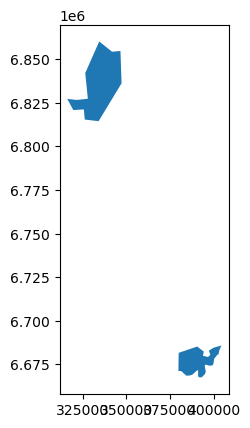

In [38]:
municipalities, name_mapping = get_municipality_codes(CITIES)
print(name_mapping)
municipalities.plot()

(('Helsinki', '091'), ('Tampere', '837'))


<AxesSubplot: >

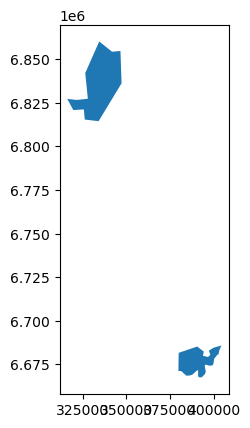

In [39]:
gdf, name_pairs = get_municipality_codes(CITIES)
print(name_pairs)
gdf.plot()

### 4.1 Downloading population data

First, the population grid will be loaded.

In [12]:
grid_layers = get_wfs_time_series(GRIDS, YEARS, CITIES, "kunta", "https://paituli.csc.fi/geoserver/paituli/wfs?")
print(len(grid_layers.keys()))
for key in grid_layers:
    print(len(grid_layers[key]))
    #print(grid_layers[key].head())

https://paituli.csc.fi/geoserver/paituli/wfs?service=WFS&version=2.0.0&request=GetFeature&outputFormat=json&srsName=EPSG:3067&cql_filter=kunta+IN+%28%27091%27%2C%20%27837%27%29&typeName=paituli:tike_vaki1km_2016
https://paituli.csc.fi/geoserver/paituli/wfs?service=WFS&version=2.0.0&request=GetFeature&outputFormat=json&srsName=EPSG:3067&cql_filter=kunta+IN+%28%27091%27%2C%20%27837%27%29&typeName=paituli:tike_vaki1km_2017
https://paituli.csc.fi/geoserver/paituli/wfs?service=WFS&version=2.0.0&request=GetFeature&outputFormat=json&srsName=EPSG:3067&cql_filter=kunta+IN+%28%27091%27%2C%20%27837%27%29&typeName=paituli:tike_vaki1km_2018
https://paituli.csc.fi/geoserver/paituli/wfs?service=WFS&version=2.0.0&request=GetFeature&outputFormat=json&srsName=EPSG:3067&cql_filter=kunta+IN+%28%27091%27%2C%20%27837%27%29&typeName=paituli:tike_vaki1km_2019
https://paituli.csc.fi/geoserver/paituli/wfs?service=WFS&version=2.0.0&request=GetFeature&outputFormat=json&srsName=EPSG:3067&cql_filter=kunta+IN+%28%27

In [2]:
!pip install OWSLib
from owslib.wfs import WebFeatureService

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 kB 3.4 MB/s eta 0:00:00a 0:00:01


from owslib.wfs import WebFeatureService
import re
wfs11 = WebFeatureService(url="https://paituli.csc.fi/geoserver/paituli/wfs?", version='2.0.0')
wfs11.identification.title
#print([operation.name for operation in wfs11.operations])
    def filter_population_typeNames(typeName):
        if any([typeName.startswith(prefix) for prefix in layer_prefixes]):
            if years is None or len(years) == 0:
                return True
            else:
                return int(typeName.split('_')[-1]) in years
        else:
            return False
            
        
filter_cols = ['kunta', 'vaesto']

property_col_names = {}
        
requested_layers = list(filter(filter_population_typeNames, list(wfs11.contents)))    
for l in requested_layers:
    for prop_name in list(wfs11.get_schema(l)['properties'].keys()):
        for col in filter_cols:
            match = re.match(prop_name, col, re.IGNORECASE)
            if match:
                property_col_names.update({l: {prop_name : wfs11.get_schema(l)['properties'][prop_name]}})
print(property_col_names)
    # print(l, ': ', 'kunta' if 'kunta' in list(wfs11.get_schema(l)['properties'].keys()) else 'KUNTA')

In [35]:
wfs11.get_schema('paituli:tike_kuntienVaesto_2015')['properties']

{'GML_ID': 'string',
 'VUOSI': 'int',
 'KUNTA': 'string',
 'NIMI': 'string',
 'NAMN': 'string',
 'TIL_VUOSI': 'int',
 'VAESTO': 'int',
 'VAESTO_P': 'double',
 'MIEHET': 'int',
 'MIEHET_P': 'double',
 'NAISET': 'int',
 'NAISET_P': 'double',
 'IKA_0_14': 'int',
 'IKA_0_14P': 'double',
 'IKA_15_64': 'int',
 'IKA_15_64P': 'double',
 'IKA_65_': 'int',
 'IKA_65_P': 'double'}